In [52]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.cluster import KMeans
from sklearn.cluster import AgglomerativeClustering
from sklearn.cluster import DBSCAN

DATA_PATH = "./data/s1.txt"
N_CLUSTERS = 15
DBSCAN_EPS = 25_000
DBSCAN_MIN_SAMPLES = 10
PALETTE = plt.get_cmap("tab20")

In [53]:
data = pd.read_csv(DATA_PATH, sep=r"\s+", header=None, names=["x", "y"])
X = data.to_numpy()
data.describe()

,x,y
count,5000.000000,5000.000000
mean,514937.556600,494709.292800
std,244465.901926,235840.852969
min,19835.000000,51121.000000
25%,320352.500000,320107.750000
50%,505338.500000,526259.500000
75%,786228.750000,713713.500000
max,961951.000000,970756.000000


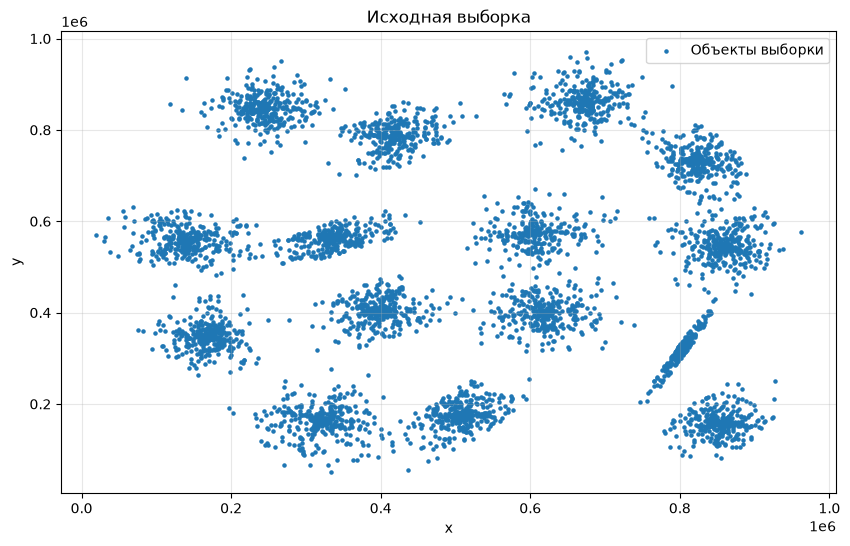

In [54]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(data["x"], data["y"], s=5, label="Объекты выборки")
ax.legend()
ax.set_title("Исходная выборка")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.grid(True, alpha=0.3);

In [55]:
def plot_clusters(ax, X, labels, title):
    for label in np.unique(labels):
        mask = labels == label
        if label == -1:
            color, name = "lightgray", "Шум"
        else:
            color, name = PALETTE(label), f"Кластер {label + 1}"
        ax.scatter(X[mask, 0], X[mask, 1], s=5, color=color, label=name)
    ax.set_title(title)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.legend(loc="upper left", bbox_to_anchor=(1, 1), fontsize="small", markerscale=3)

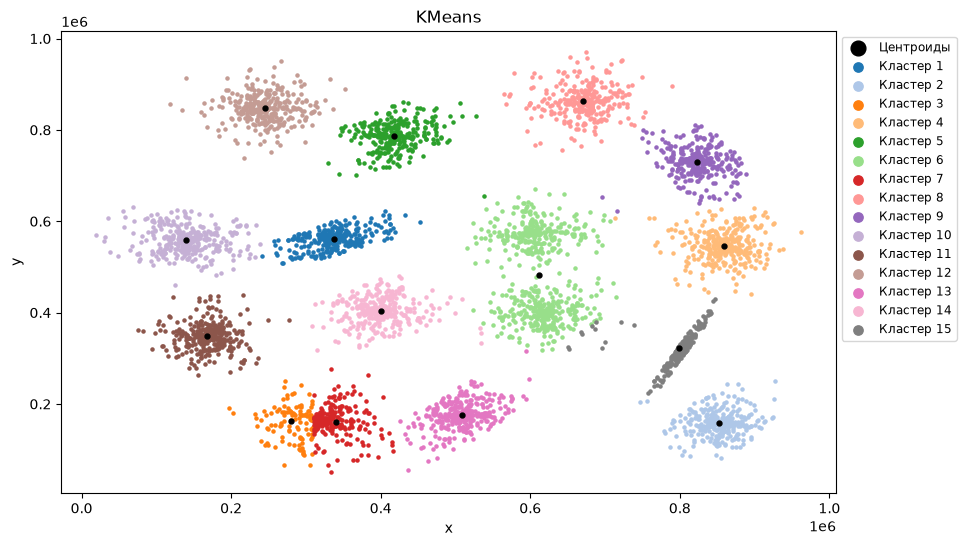

In [75]:
kmeans = KMeans(n_clusters=N_CLUSTERS, n_init=1, random_state=64)
kmeans_labels = kmeans.fit_predict(X)
centers = kmeans.cluster_centers_

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(centers[:, 0], centers[:, 1], marker=".", s=50, color="black",
           label="Центроиды", zorder=2)
plot_clusters(ax, X, kmeans_labels, "KMeans")

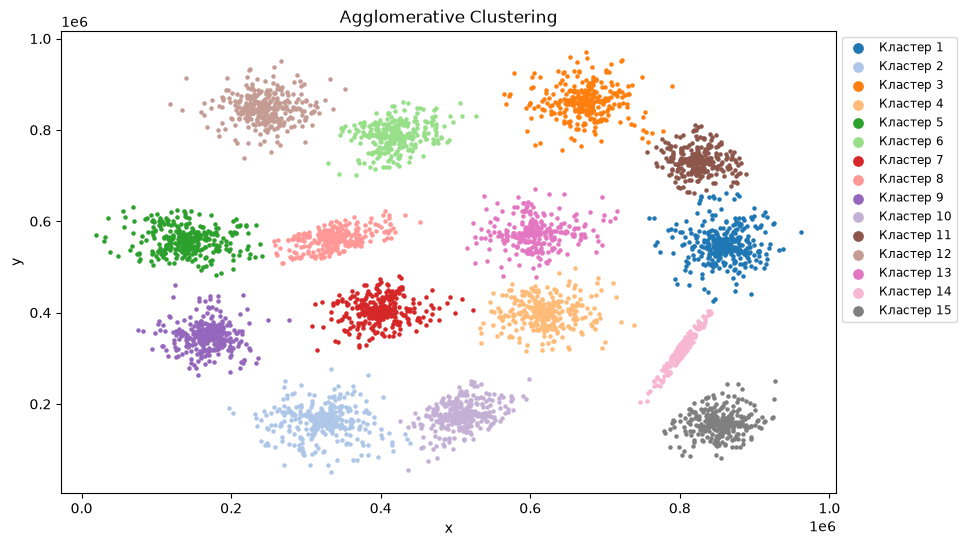

In [57]:
agglo = AgglomerativeClustering(n_clusters=N_CLUSTERS)
agglo_labels = agglo.fit_predict(X)

fig, ax = plt.subplots(figsize=(10, 6))
plot_clusters(ax, X, agglo_labels, "Agglomerative Clustering")

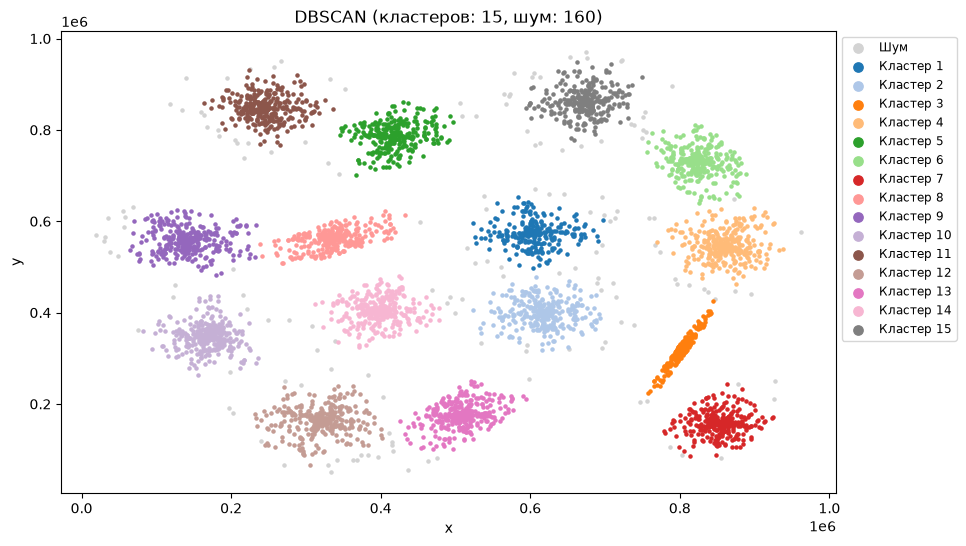

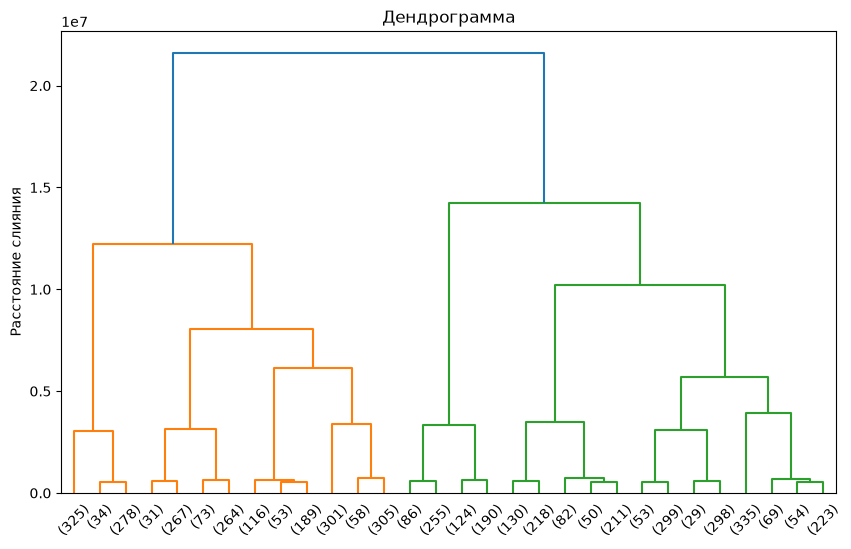

In [62]:
dbscan = DBSCAN(eps=DBSCAN_EPS, min_samples=DBSCAN_MIN_SAMPLES)
dbscan_labels = dbscan.fit_predict(X)

fig, ax = plt.subplots(figsize=(10, 6))
plot_clusters(ax, X, dbscan_labels,
              f"DBSCAN (кластеров: {len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)}, "
              f"шум: {(dbscan_labels == -1).sum()})")

Z = linkage(X, method="ward")                       

fig, ax = plt.subplots(figsize=(10, 6))
dendrogram(Z, ax=ax, truncate_mode="lastp", p=30)
ax.set_title("Дендрограмма")
ax.set_ylabel("Расстояние слияния")
plt.show()

Все три метода выделили в выборке s1 15 кластеров, и разбиения почти совпадают.

KMeans справился лучше всех по соотношению качества и простоты: быстро работает,  получил чёткие кластеры, и центроиды совпадают с центрами скоплений.
Недостатки: число кластеров нужно задать самому, результат зависит от начальной инициализации (поэтому фиксируется `random_state` и выполняется несколько запусков `n_init`), метод чувствителен к выбросам и плохо работает с кластерами невыпуклой формы или разной плотности.

AgglomerativeClustering дал практически то же разбиение. Результат детерминирован. 
Недостатки: квадратичная сложность по времени и памяти, поэтому метод плохо масштабируется на большие выборки; объединения кластеров необратимы; результат сильно зависит от выбора связывания (например, `single` склеивает кластеры «цепочками»).

DBSCAN не требует задавать число кластеров и умеет выделять шум: 160 точек на разреженных краях кластеров отмечены как шум, поэтому Silhouette на оставшихся точках самая водит кластеры произвольной формы и устойчив к выбросам.

Итог: для данных с компактными круглыми кластерами  лучше всего подходит KMeans. Agglomerative Clustering стоит выбрать, когда выборка небольшая.DBSCAN стоит выбрать, когда число кластеров неизвестно, они имеют сложную форму или в данных есть шум и выбросы.